# IND320 Dashboard – del 3

Denne notebooken dokumenterer del 3 av IND320-prosjektet: værdata fra open-meteo for NVE sine regioner og strømprisområder, analyse av uteliggere og anomalier (SPC og LOF), STL-dekomponering og spektrogram av fyllingsgraden, og oppdatering av Streamlit-appen.

## Lenker

- GitHub-repository: https://github.com/Kaja321/ind320-dashboard-kaja321
- Publisert Streamlit-app: https://ind320-dashboard-kaja321.streamlit.app/
- Screencast: *legges inn når videoen er laget*

## Bruk av kunstig intelligens

Jeg har brukt Claude (Anthropic) som støtte gjennom hele del 3. KI ble brukt til å:
- gå gjennom notebooken mot kravene i oppgaven og peke på hva som manglet
- finne ut hvilke git-kommandoer som trengtes for å lage den nye mappestrukturen
- feilsøke problemer med Python-miljøet (geopandas og pyproj på min Mac)
- regne ut grensene hos open-meteo og foreslå nedlasting i porsjoner med cache
- foreslå og forbedre kode for SPC, LOF, STL og spektrogrammet, og for de nye Streamlit-sidene
- foreslå formuleringer til kommentarer, tolkninger og markdown-tekst

Jeg har selv kjørt og testet all kode, vurdert forslagene og tilpasset dem, og tatt valgene underveis. For eksempel valgte jeg å bruke 100 punkter per område, slik læreren gjorde i forelesningen. Jeg har spurt om forklaringer når jeg ikke forsto koden eller feilmeldingene, slik at jeg kan stå for det som er levert.

## Prosjektlogg

### Oppstart og struktur

Etter tilbakemeldingen på del 2 ryddet jeg i repoet. Notebookene ligger nå i notebooks/, opptakene i recordings/ og kartfilene i data/. Home.py, pages/ og requirements.txt ble liggende øverst, fordi Streamlit Cloud leter etter dem der. Stiene i notebookene måtte få ../ foran. Alt nytt arbeid ble gjort på branchen part3, som ble merget inn i main etter at peer review og tilbakemelding på del 2 var ferdige.

### Regioner og værdata

Kartlagene for budområder og NVE-regioner lastet jeg ned fra NVE Atlas som shapefiler. Det tok litt tid å finne nedlastingen, som ligger under «Vis tabell» i menyen til hvert kartlag. Da jeg leste inn regionene, ble «Førde» til «FÃ¸rde» og «RØ» til «RÃ˜». Fila var lagret som UTF-8, og det løste seg da jeg oppga dette ved innlesingen. Geopandas lot seg ikke installere direkte på min Intel-Mac, så jeg måtte bruke en eldre versjon av pakken pyproj. Regionene RS og RØ ble slått sammen til VASS 1, og RM og RN til VASS 3, slik at områdene passer med magasinstatistikken.

Jeg trakk 1000 tilfeldige punkter i hvert område, men gratisversjonen av open-meteo tåler ikke et helt år for 1000 punkter. Funksjonen bruker derfor 100 punkter som standard, laster ned i porsjoner og lagrer svarene i en cache, så de ikke lastes ned på nytt. Alle tider er i UTC, som i del 2.

### Analyse

SPC ga 6,3 % uteliggere for nedbør, men bare 0,34 % for temperatur. Nedbør er skjevfordelt, og det viste meg at metoden passer best for data som er nær normalfordelt. LOF fikk både tid og verdi, slik at hver time blir sammenlignet med timene rundt seg. STL og spektrogrammet viser tydelig den årlige syklusen i fyllingsgraden, og STL viser også tørre år som 2003 og 2010.

### Streamlit

Funksjonene ble flyttet til en felles fil, functions.py, som alle sidene bruker. Områdevalget ligger nå i sidebaren og huskes mellom sidene, slik at værdataene alltid følger samme område som magasindataene. Værdataene lastes ned skjult i bakgrunnen med 20 punkter og caching, så appen svarer raskt. De to nye sidene har faner for STL og spektrogram, og for SPC og LOF. Sidene ble sortert etter tema, og testsiden ble fjernet. Underveis feilet spektrogrammet fordi return fig manglet i funksjonen. Da lærte jeg å bruke feilmeldingene i Streamlit til å finne riktig fil og linje.


## Dataanalyse

### Regioner fra NVE Atlas

In [2]:
import geopandas as gpd

# Leser NVE sine regioner og strømprisområdene (budområdene) fra shapefilene.
# Stien starter med ../ fordi notebooken ligger i notebooks/
regions = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding="utf-8")
bid_zones = gpd.read_file("../data/Budomrader/Budomrader.shp")

# Viser koordinatsystem og innhold, så vi ser at alle fem områdene er med
print("Regioner:", len(regions), "rader, koordinatsystem:", regions.crs)
print(regions.drop(columns="geometry"))
print("\nBudområder:", len(bid_zones), "rader, koordinatsystem:", bid_zones.crs)
print(bid_zones.drop(columns="geometry"))

Regioner: 5 rader, koordinatsystem: EPSG:25833
   OBJECTID REGION         REGIONNAVN POSTNUMMER   POSTSTED  \
0       1.0     RV        Region Vest       6801      Førde   
1       2.0     RM  Region Midt-Norge       7030  Trondheim   
2       3.0     RN        Region Nord       8514     Narvik   
3       4.0     RØ         Region Øst       2307      Hamar   
4       5.0     RS         Region Sør       3103   Tønsberg   

                BESØKSADR            ADRESSE  
0       Naustdalsveien 1B        Postboks 53  
1  Abelsgate 9, Trondheim        Abelsgate 9  
2       Kongensgate 52-54  Kongensgate 52-54  
3           Vangsvegen 73      Postboks 4223  
4   Anton Jenssens gate 7      Postboks 2124  

Budområder: 5 rader, koordinatsystem: EPSG:25833
   objectid budomr  globalid    st_area(sh    st_perimet
0       1.0   NO 1       NaN  6.052902e+10  1.657761e+06
1       2.0   NO 2       NaN  6.875969e+10  1.256473e+06
2       3.0   NO 3       NaN  1.042199e+11  1.773323e+06
3       4.0   

### Fra regioner til områder i magasinstatistikken

Magasinstatistikken bruker strømprisområdene EL 1–5 og vassdragsområdene VASS 1–3. Budområdene fra NVE Atlas («NO 1»–«NO 5») har samme nummer som EL 1–5. NVE sine fem regioner slås sammen til tre vassdragsområder, slik oppgaven beskriver: Øst = RS + RØ (VASS 1), Vest = RV (VASS 2) og Nord = RM + RN (VASS 3). VASS 4 (Nord-Norge) har ingen magasindata, så RN tas med i VASS 3.

     area
0    EL 1
1    EL 2
2    EL 3
3    EL 4
4    EL 5
5  VASS 1
6  VASS 2
7  VASS 3


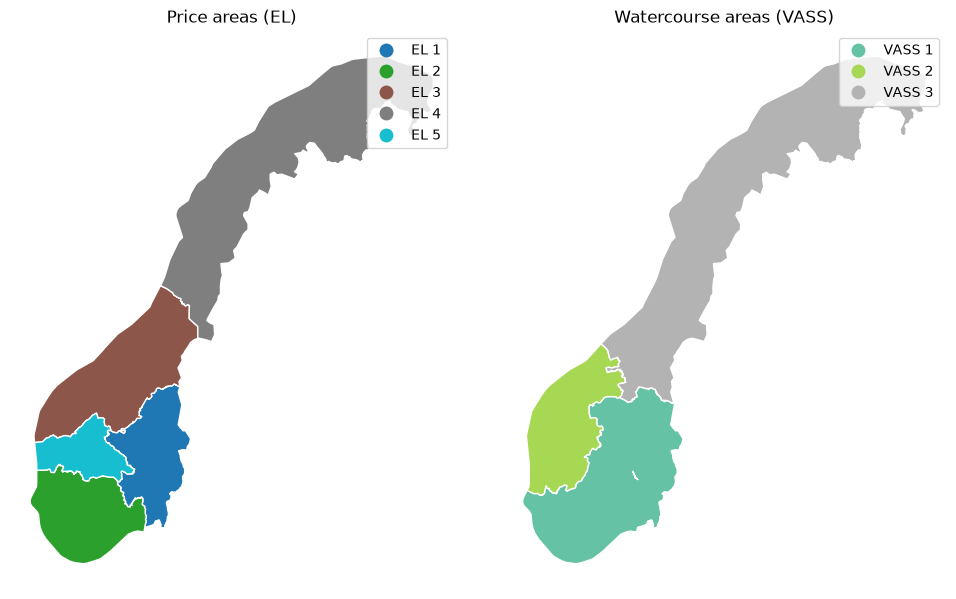

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Kobler NVE-regionene til vassdragsområdene i magasinstatistikken
region_to_area = {"RS": "VASS 1", "RØ": "VASS 1",
                  "RV": "VASS 2",
                  "RM": "VASS 3", "RN": "VASS 3"}
regions["area"] = regions["REGION"].map(region_to_area)

# dissolve slår sammen kartformene som har samme område (f.eks. RS og RØ blir én form)
vass_areas = regions.dissolve(by="area").reset_index()[["area", "geometry"]]

# Budområdene: "NO 1" blir "EL 1", så navnene passer med magasinstatistikken
bid_zones["area"] = bid_zones["budomr"].str.replace("NO", "EL")
el_areas = bid_zones[["area", "geometry"]]

# Samler alle åtte områdene i én tabell (begge er i samme koordinatsystem, EPSG:25833)
areas = pd.concat([el_areas, vass_areas], ignore_index=True)
print(areas[["area"]])

# Tegner områdene ved siden av hverandre for å sjekke at sammenslåingen ble riktig
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
el_areas.plot(column="area", ax=axs[0], legend=True, edgecolor="white", cmap="tab10")
axs[0].set_title("Price areas (EL)")
vass_areas.plot(column="area", ax=axs[1], legend=True, edgecolor="white", cmap="Set2")
axs[1].set_title("Watercourse areas (VASS)")
for ax in axs:
    ax.set_axis_off()   # skjuler aksene med meter-koordinater, som ikke sier leseren noe
plt.tight_layout()
plt.show()

### Tilfeldige punkter for nedlasting av værdata

For hvert av de åtte områdene trekkes 1000 tilfeldige punkter med `sample_points`, slik læreren viste i forelesningen. Punktene trekkes i UTM33 (meter), så de blir jevnt fordelt over arealet, og gjøres deretter om til lengde- og breddegrad (WGS84), som open-meteo bruker. `rng=42` gjør at de samme punktene trekkes hver gang. Først brukte jeg `random_state=42`, men den ble ignorert av geopandas, og punktene ble forskjellige ved hver kjøring. Punktene lagres i `data/locations.csv`, slik at Streamlit-appen kan bruke dem uten geopandas.

In [ ]:
# Antall tilfeldige punkter per område
K = 1000

# Trekker K tilfeldige punkter inne i hvert område. Resultatet er én MultiPoint per område.
# rng=42 gjør at de samme punktene trekkes hver gang (random_state blir ignorert av geopandas).
points_per_area = areas["geometry"].sample_points(size=K, rng=42)

# Gjør om fra UTM33 (meter) til WGS84 (lengde- og breddegrad), som open-meteo bruker
points_wgs84 = points_per_area.to_crs(epsg=4326)

# Går gjennom hvert område og hvert punkt, og lagrer koordinatene i en liste
rows = []
for idx, multipoint in points_wgs84.items():
    area = areas.loc[idx, "area"]
    for point in multipoint.geoms:
        rows.append({"area": area, "longitude": point.x, "latitude": point.y})

# Gjør lista om til en vanlig tabell og lagrer den
locations = pd.DataFrame(rows)
locations.to_csv("../data/locations.csv", index=False)

# Sjekker at hvert område har 1000 punkter
print(locations.groupby("area").size())
locations.head()

area
EL 1      1000
EL 2      1000
EL 3      1000
EL 4      1000
EL 5      1000
VASS 1    1000
VASS 2    1000
VASS 3    1000
dtype: int64


,area,longitude,latitude
0,EL 1,9.572274,60.774359
1,EL 1,11.306508,61.441004
2,EL 1,8.182614,61.252858
3,EL 1,11.531451,62.013539
4,EL 1,10.656945,61.355957


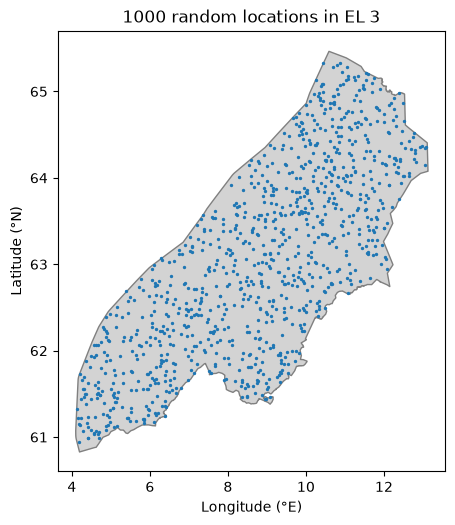

In [5]:
# Tegner punktene for NO3 (EL 3) oppå området, for å se at de ligger inne i området
area_name = "EL 3"
fig, ax = plt.subplots(figsize=(5, 6))
areas[areas["area"] == area_name].to_crs(epsg=4326).plot(ax=ax, color="lightgrey", edgecolor="grey")
points = locations[locations["area"] == area_name]
ax.scatter(points["longitude"], points["latitude"], s=2, color="tab:blue")
ax.set_title(f"1000 random locations in {area_name}")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
plt.show()

### Nedlasting av værdata fra open-meteo

Værdataene hentes fra open-meteo sitt historiske API (ERA5-reanalyse, timesverdier). Funksjonen `download_weather` tar et område (f.eks. «EL 3») og en tidsperiode, slår opp de tilfeldige punktene for området i `locations` og laster ned værdata for dem.

Gratisversjonen av open-meteo har en grense for hvor mye som kan lastes ned. En forespørsel teller omtrent som antall punkter × antall dager / 14. Ett år for 1000 punkter tilsvarer rundt 26 000 kall, mens grensen er 10 000 per døgn. Derfor bruker funksjonen 100 punkter som standard, slik læreren også gjorde, og laster ned 20 punkter om gangen med en pause mellom. Svarene lagres i en cache i `No_sync/`, så de samme dataene ikke lastes ned på nytt.

I tillegg til nedbør og temperatur hentes regn, snø, vindhastighet og luftfuktighet. Snø er relevant for vannkraft, fordi snø som faller om vinteren først renner inn i magasinene når den smelter om våren.

In [6]:
import time
import openmeteo_requests
import requests_cache
from retry_requests import retry

# Oppsett av open-meteo-klienten, som i koden open-meteo lager på nettsiden.
# requests_cache lagrer svarene i No_sync/, så samme forespørsel ikke lastes ned to ganger.
# retry prøver på nytt opptil 5 ganger hvis en forespørsel feiler.
cache_session = requests_cache.CachedSession("../No_sync/openmeteo_cache", expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

URL = "https://archive-api.open-meteo.com/v1/archive"

# Værvariablene som lastes ned. Rekkefølgen er viktig, fordi svaret bruker den samme rekkefølgen.
VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall",
             "wind_speed_10m", "relative_humidity_2m"]


def download_weather(area, start_date, end_date, n_points=100, batch_size=20, pause=60):
    """Laster ned værdata (ERA5, timesverdier) for et område og en periode.

    area:       områdenavn som i magasinstatistikken, f.eks. "EL 3" eller "VASS 1"
    start_date: første dag, f.eks. "2024-01-01"
    end_date:   siste dag, f.eks. "2024-12-31"
    n_points:   antall tilfeldige punkter som brukes (av de 1000 i locations)
    batch_size: antall punkter per forespørsel, så vi holder oss under grensen hos open-meteo
    pause:      sekunder å vente mellom forespørslene

    Returnerer en tabell med gjennomsnittet over alle punktene for hver time (tid i UTC).
    """
    # Slår opp punktene for området
    points = locations[locations["area"] == area].head(n_points)

    all_points = []   # én tabell per punkt samles her
    for start in range(0, len(points), batch_size):
        batch = points.iloc[start:start + batch_size]

        params = {
            "latitude": batch["latitude"].tolist(),
            "longitude": batch["longitude"].tolist(),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": VARIABLES,
            "models": "era5",
        }
        responses = openmeteo.weather_api(URL, params=params)

        # Ett svar per punkt. Gjør hvert svar om til en tabell med tid og alle variablene.
        for response in responses:
            hourly = response.Hourly()
            # Tidene kommer som sekunder siden 1970 i UTC. utc=True gjør at sommertid ikke lager problemer.
            df = pd.DataFrame({"time": pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left",
            )})
            for i, variable in enumerate(VARIABLES):
                df[variable] = hourly.Variables(i).ValuesAsNumpy()
            all_points.append(df)

        # Venter før neste porsjon, men ikke etter den siste
        if start + batch_size < len(points):
            print(f"Lastet ned {start + batch_size} av {len(points)} punkter, venter {pause} s ...")
            time.sleep(pause)

    # Slår sammen alle punktene og tar gjennomsnittet for hver time
    weather = pd.concat(all_points)
    return weather.groupby("time").mean()

In [7]:
# Liten test: 5 punkter i to uker, så vi ser at funksjonen virker uten å bruke mye av kvoten
weather_test = download_weather("EL 3", "2024-01-01", "2024-01-14", n_points=5)
print("Antall rader:", len(weather_test))   # 14 dager × 24 timer = 336
weather_test.head()

Antall rader: 336


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,relative_humidity_2m
time,,,,,,
2024-01-01 00:00:00+00:00,-4.163,0.0,0.0,0.0,26.461487,69.419708
2024-01-01 01:00:00+00:00,-4.303,0.0,0.0,0.0,26.050426,69.395950
2024-01-01 02:00:00+00:00,-4.223,0.0,0.0,0.0,26.480764,68.979599
2024-01-01 03:00:00+00:00,-4.233,0.0,0.0,0.0,26.938511,68.707458
2024-01-01 04:00:00+00:00,-4.153,0.0,0.0,0.0,27.378195,68.478004


In [8]:
# Laster ned værdata for NO3 (EL 3) for hele 2024 med 100 punkter, slik oppgaven ber om.
# Det tar rundt 5 minutter på grunn av pausene mellom porsjonene.
weather_no3 = download_weather("EL 3", "2024-01-01", "2024-12-31")

print("Antall rader:", len(weather_no3))   # 2024 er skuddår: 366 dager × 24 timer = 8784
weather_no3.describe().round(2)

Lastet ned 20 av 100 punkter, venter 60 s ...
Lastet ned 40 av 100 punkter, venter 60 s ...
Lastet ned 60 av 100 punkter, venter 60 s ...
Lastet ned 80 av 100 punkter, venter 60 s ...
Antall rader: 8784


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,relative_humidity_2m
count,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00
mean,5.27,0.20,0.16,0.03,14.29,79.06
std,6.76,0.27,0.24,0.06,5.71,9.08
min,-12.26,0.00,0.00,0.00,3.75,42.83
25%,0.72,0.01,0.01,0.00,10.08,73.98
50%,4.90,0.10,0.07,0.00,13.17,80.89
75%,10.62,0.28,0.22,0.02,17.65,85.69
max,22.16,2.68,2.10,0.97,45.31,96.38


## Uteliggere med SPC (Statistical Process Control)

Nedbøren høypassfiltreres med Discrete Cosine Transform (DCT): de laveste frekvensene, altså sesongen og lange værperioder, settes til null, og det som blir igjen er sesongjusterte variasjoner (SATV). Grensene mellom innliggere og uteliggere regnes ut fra SATV med robust statistikk over hele året: medianen og MAD × 1,4826 som robust standardavvik. Grensene legges på den langsomme kurven (nedbør − SATV), slik at de følger nivået gjennom året. SATV plottes ikke, men brukes bare til å finne grensene.

Frekvensgrensen (`cutoff`) og antall standardavvik (`n_std`) er parametere. Med `cutoff=100` fjernes svingninger som er langsommere enn omtrent én uke.

In [9]:
import numpy as np
from scipy.fft import dct, idct
from scipy import stats

# Lesbare navn med enheter til aksene i plottene (på engelsk, som i appen)
LABELS = {"temperature_2m": "Temperature (°C)", "precipitation": "Precipitation (mm)",
          "rain": "Rain (mm)", "snowfall": "Snowfall (cm)",
          "wind_speed_10m": "Wind speed (km/h)", "relative_humidity_2m": "Relative humidity (%)"}


def spc_outliers(weather, column="precipitation", cutoff=100, n_std=3):
    """Finner uteliggere med SPC basert på SATV (høypassfiltrert serie med DCT).

    weather: tabell med tid som indeks (fra download_weather)
    column:  variabelen som analyseres, standard er nedbør
    cutoff:  DCT-indeks. Frekvenser under denne settes til null (high-pass).
    n_std:   antall robuste standardavvik til grensene

    Returnerer figuren og en oversikt over uteliggerne.
    """
    values = weather[column].values

    # 1. DCT: fra tidsserie til frekvenser (samme type og norm som i D2Dbook)
    coeffs = dct(values, type=1, norm="forward")

    # 2. High-pass: fjerner de langsomme svingningene og gjør om tilbake. Resultatet er SATV.
    coeffs_high = coeffs.copy()
    coeffs_high[:cutoff] = 0
    satv = idct(coeffs_high, type=1, norm="forward")

    # 3. Den langsomme kurven (det som ble fjernet)
    trend = values - satv

    # 4. Robust statistikk på SATV for hele året: median og MAD skalert til standardavvik (× 1,4826)
    center = np.median(satv)
    sigma = stats.median_abs_deviation(satv, scale="normal")

    # 5. Grenser rundt den langsomme kurven, og uteliggere der SATV er utenfor grensene
    upper = trend + center + n_std * sigma
    lower = trend + center - n_std * sigma
    is_outlier = (satv > center + n_std * sigma) | (satv < center - n_std * sigma)

    # Plott: serien, grensene og uteliggerne i en kontrastfarge (SATV plottes ikke)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(weather.index, values, color="tab:blue", linewidth=0.6, label=LABELS[column])
    ax.plot(weather.index, upper, color="grey", linestyle="--", linewidth=0.8, label="SPC limits")
    ax.plot(weather.index, lower, color="grey", linestyle="--", linewidth=0.8)
    ax.scatter(weather.index[is_outlier], values[is_outlier], color="tab:red", s=10,
               zorder=3, label="Outliers")
    ax.set_title(f"{LABELS[column]} with SPC limits "
                 f"(cutoff = {cutoff}, {n_std} robust SDs)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(LABELS[column])
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    plt.tight_layout()

    # Oversikt over uteliggerne (på engelsk, så den kan vises i appen)
    outliers = weather.loc[is_outlier, [column]]
    summary = {
        "number of outliers": int(is_outlier.sum()),
        "share of outliers (%)": round(float(100 * is_outlier.mean()), 2),   # float() gir penere utskrift
        "robust SD (SATV)": round(float(sigma), 3),
    }
    return fig, summary, outliers

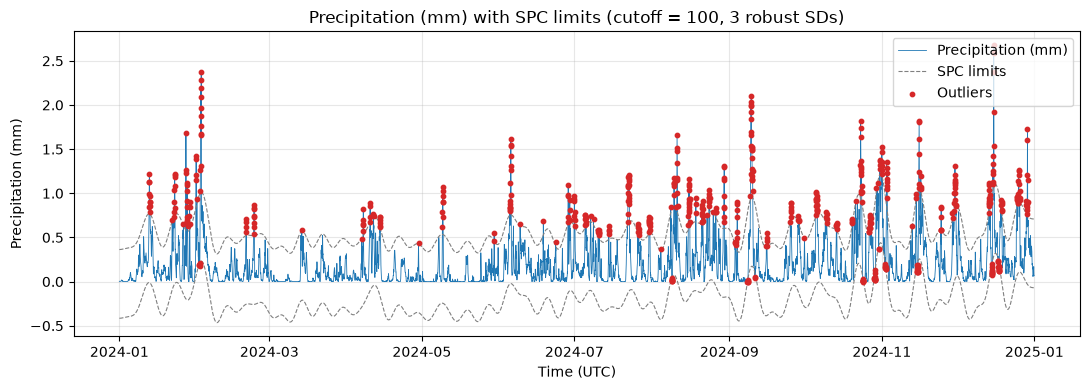

{'number of outliers': 552, 'share of outliers (%)': 6.28, 'robust SD (SATV)': 0.13}


,precipitation
time,
2024-12-15 18:00:00+00:00,2.677
2024-12-15 17:00:00+00:00,2.594
2024-02-02 18:00:00+00:00,2.374
2024-12-15 19:00:00+00:00,2.372
2024-02-02 17:00:00+00:00,2.282


In [10]:
# Tester funksjonen med standardverdiene (nedbør, cutoff = 100, 3 standardavvik)
fig, summary, outliers = spc_outliers(weather_no3)
plt.show()
print(summary)

# De fem største uteliggerne
outliers.sort_values("precipitation", ascending=False).head()

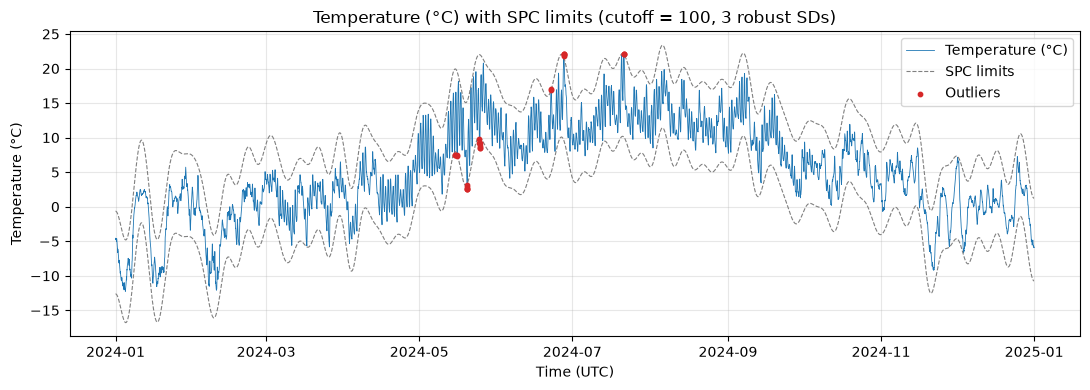

{'number of outliers': 25, 'share of outliers (%)': 0.28, 'robust SD (SATV)': 1.995}


,temperature_2m
time,
2024-05-15 02:00:00+00:00,7.48464
2024-05-15 03:00:00+00:00,7.42614
2024-05-16 02:00:00+00:00,7.46664
2024-05-16 03:00:00+00:00,7.36914
2024-05-20 00:00:00+00:00,2.91214


In [11]:
# Tester at parameterne virker: temperatur i stedet for nedbør
fig, summary, outliers = spc_outliers(weather_no3, column="temperature_2m", cutoff=100, n_std=3)
plt.show()
print(summary)
outliers.head()

**Tolkning**

*Nedbør:* 6,3 % av timene er markert som uteliggere, altså målinger som skiller seg tydelig ut fra resten. Det er mye, for hvis dataene var jevnt fordelt rundt et gjennomsnitt, ville vi ventet rundt 0,3 %. Nedbør oppfører seg ikke slik: det meste av tiden regner det nesten ingenting, og innimellom kommer korte, kraftige byger. Grensene blir derfor smale, og mange av bygene havner utenfor. De største uteliggerne var 15. desember og 2. februar. Den nedre grensen går under null, noe som ikke gir mening for nedbør, men metoden lager alltid grensene like langt over og under kurven.

*Temperatur:* Her er bare 0,34 % av timene uteliggere, som er nær det vi ville ventet. Uteliggerne er noen kalde netter i midten av mai og noen uvanlig varme timer i juni og juli.

*Konklusjon:* Metoden passer bedre for temperatur enn for nedbør, fordi temperaturen endrer seg jevnere og ikke har plutselige topper på samme måte.

## Anomalier med LOF (Local Outlier Factor)

LOF finner målinger som skiller seg ut fra målingene rett rundt seg. For hver time ser metoden på de nærmeste naboene og sjekker om timen ligger mye lenger unna dem enn naboene ligger fra hverandre. Er den det, regnes den som en anomali, altså en uvanlig måling.

Metoden får både tidspunktet og temperaturen. Da blir hver time sammenlignet med timene rundt seg, og ikke med hele året. Uten tiden ville LOF bare ha funnet de kaldeste og varmeste timene i året. Tid og temperatur gjøres om til samme skala før analysen, slik at de teller like mye.

Andelen anomalier (`contamination`) kan velges og er 1 % som standard. Hver time sammenlignes med sine 20 nærmeste naboer, som i D2Dbook.

In [12]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler


def lof_anomalies(weather, column="temperature_2m", contamination=0.01, n_neighbors=20):
    """Finner anomalier med Local Outlier Factor (LOF).

    weather:       tabell med tid som indeks (fra download_weather)
    column:        variabelen som analyseres, standard er temperatur
    contamination: andelen anomalier, standard 1 %
    n_neighbors:   antall naboer LOF sammenligner med

    Returnerer figuren og en oversikt over anomaliene.
    """
    values = weather[column].values

    # Tid som antall timer fra start, så LOF ser hvilke timer som ligger nær hverandre
    hours = (weather.index - weather.index[0]) / pd.Timedelta(hours=1)

    # Skalerer tid og verdi til gjennomsnitt 0 og standardavvik 1, så de teller like mye
    X = StandardScaler().fit_transform(np.column_stack([hours, values]))

    # LOF gir -1 for anomalier og 1 for vanlige punkter
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_anomaly = lof.fit_predict(X) == -1

    # Plott: serien og anomaliene i en kontrastfarge
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(weather.index, values, color="tab:blue", linewidth=0.6, label=LABELS[column])
    ax.scatter(weather.index[is_anomaly], values[is_anomaly], color="tab:red", s=10,
               zorder=3, label="Anomalies (LOF)")
    ax.set_title(f"{LABELS[column]} with LOF anomalies "
                 f"(proportion = {contamination * 100:g} %, {n_neighbors} neighbours)")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(LABELS[column])
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    plt.tight_layout()

    # Oversikt over anomaliene (på engelsk, så den kan vises i appen)
    anomalies = weather.loc[is_anomaly, [column]]
    summary = {
        "number of anomalies": int(is_anomaly.sum()),
        "share of anomalies (%)": round(float(100 * is_anomaly.mean()), 2),
        "lowest anomaly": round(float(anomalies[column].min()), 2),
        "highest anomaly": round(float(anomalies[column].max()), 2),
    }
    return fig, summary, anomalies

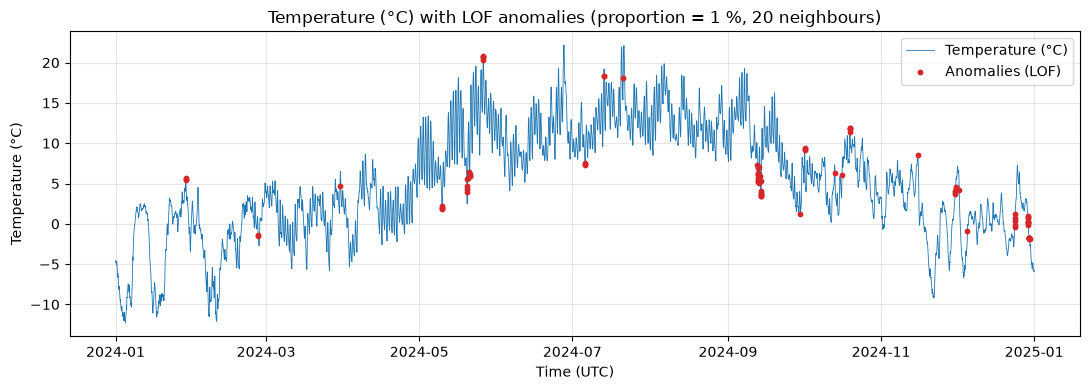

{'number of anomalies': 88, 'share of anomalies (%)': 1.0, 'lowest anomaly': -1.94, 'highest anomaly': 20.79}


,temperature_2m
time,
2024-01-28 22:00:00+00:00,5.55714
2024-01-28 23:00:00+00:00,5.72064
2024-01-29 00:00:00+00:00,5.39864
2024-02-26 20:00:00+00:00,-1.39236
2024-02-26 21:00:00+00:00,-1.56836


In [13]:
# Tester funksjonen med standardverdiene (temperatur, 1 % anomalier)
fig, summary, anomalies = lof_anomalies(weather_no3)
plt.show()
print(summary)
anomalies.head()

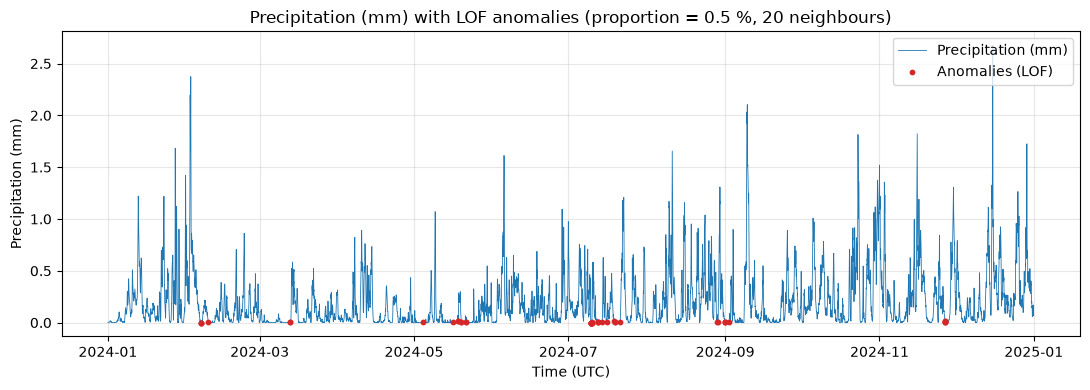

{'number of anomalies': 44, 'share of anomalies (%)': 0.5, 'lowest anomaly': 0.0, 'highest anomaly': 0.02}


,precipitation
time,
2024-05-18 07:00:00+00:00,0.016
2024-05-18 06:00:00+00:00,0.014
2024-11-26 19:00:00+00:00,0.013
2024-11-26 20:00:00+00:00,0.012
2024-07-19 06:00:00+00:00,0.011


In [14]:
# Tester at parameterne virker: nedbør i stedet for temperatur, og 0,5 % anomalier
fig, summary, anomalies = lof_anomalies(weather_no3, column="precipitation", contamination=0.005)
plt.show()
print(summary)
anomalies.sort_values("precipitation", ascending=False).head()

**Tolkning**

*Temperatur:* LOF markerer 1 % av timene som anomalier, slik vi ba om. Anomaliene er ikke de kaldeste eller varmeste timene i året, men timer som skiller seg ut fra timene rundt seg. Et eksempel er 28. januar, da det plutselig var over 6 °C midt i en kald periode. Den kaldeste perioden i januar er ikke markert, fordi mange timer på rad var like kalde og derfor har mange naboer.

*Nedbør:* Her havner anomaliene nesten på null. Det er svært mange timer med null eller nesten null nedbør, og de ligger tett sammen. En time med bare litt nedbør blir da regnet som isolert, mens de store bygene ikke blir markert, fordi de kommer i grupper med flere våte timer på rad.

*Konklusjon:* LOF fungerer godt for temperatur, men dårlig for nedbør, fordi nedbøren har så mange like verdier rundt null.

## Fyllingsgrad: STL og spektrogram

De to siste analysene bruker fyllingsgraden fra magasinstatistikken til NVE, med ukentlige målinger. Som standard brukes NO3 (EL 3), samme område som værdataene over.

In [15]:
import requests

# Henter magasinstatistikken direkte fra NVE sitt API (samme som i del 2)
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
response = requests.get(url)
response.raise_for_status()   # stopper med en feilmelding hvis forespørselen mislyktes
reservoirs = pd.DataFrame(response.json())

# Datoformat og områdenavn som i appen og i locations (f.eks. "EL 3")
reservoirs["dato_Id"] = pd.to_datetime(reservoirs["dato_Id"])
reservoirs["area"] = reservoirs["omrType"] + " " + reservoirs["omrnr"].astype(str)

# Viser hvilken periode dataene dekker for NO3
no3 = reservoirs[reservoirs["area"] == "EL 3"]
print("NO3:", no3["dato_Id"].min().date(), "til", no3["dato_Id"].max().date(), "-", len(no3), "uker")

NO3: 1995-01-08 til 2026-11-01 - 1661 uker


### STL-dekomponering

STL deler fyllingsgraden i tre deler: en trend som viser utviklingen over flere år, en sesong som viser mønsteret som gjentar seg hvert år, og en rest som viser avvik fra et vanlig år. Til sammen blir de tre delene den opprinnelige serien. Perioden er 52 uker. Glattingen av sesong (`seasonal`) og trend (`trend`), og om metoden skal være robust mot store avvik (`robust`), er parametere.

In [16]:
from statsmodels.tsa.seasonal import STL


def stl_plot(reservoirs, area="EL 3", period=52, seasonal=13, trend=105, robust=False):
    """STL-dekomponering av fyllingsgraden for ett område.

    reservoirs: magasinstatistikken fra NVE
    area:       område, f.eks. "EL 3" eller "VASS 1"
    period:     antall uker i én sesong (ett år)
    seasonal:   glatting av sesongen (oddetall)
    trend:      glatting av trenden i uker (oddetall, større enn period)
    robust:     True gjør metoden mindre følsom for store avvik

    Returnerer figuren.
    """
    # Fyllingsgraden for området som en tidsserie med dato som indeks, sortert etter dato
    series = (reservoirs[reservoirs["area"] == area]
              .sort_values("dato_Id")
              .set_index("dato_Id")["fyllingsgrad"] * 100)   # * 100 gir prosent

    # STL med valgte parametere
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    # Plotter de fire delene under hverandre: data, trend, sesong og rest
    fig = result.plot()
    fig.set_size_inches(10, 7)
    fig.suptitle(f"STL of fill level (%) for {area} "
                 f"(seasonal = {seasonal}, trend = {trend}, robust = {robust})", y=1.01)
    for ax in fig.axes:
        ax.grid(alpha=0.3)

    # Lesbare navn på aksene (på engelsk, som i appen)
    fig.axes[0].set_title("")                     # fjerner den doble overskriften
    fig.axes[0].set_ylabel("Fill level (%)")
    fig.axes[1].set_ylabel("Trend")
    fig.axes[2].set_ylabel("Season")
    fig.axes[3].set_ylabel("Residual")
    fig.axes[-1].set_xlabel("Date")

    # Mindre prikker i restplottet, så det blir lettere å lese
    fig.axes[3].lines[0].set_markersize(2)
    plt.tight_layout()
    return fig

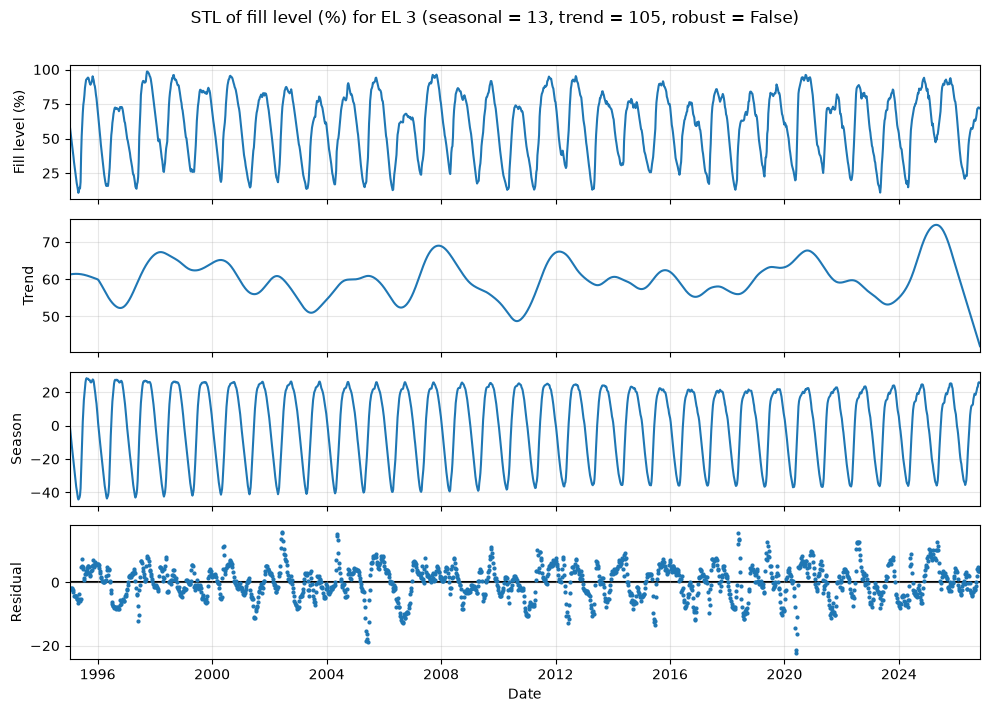

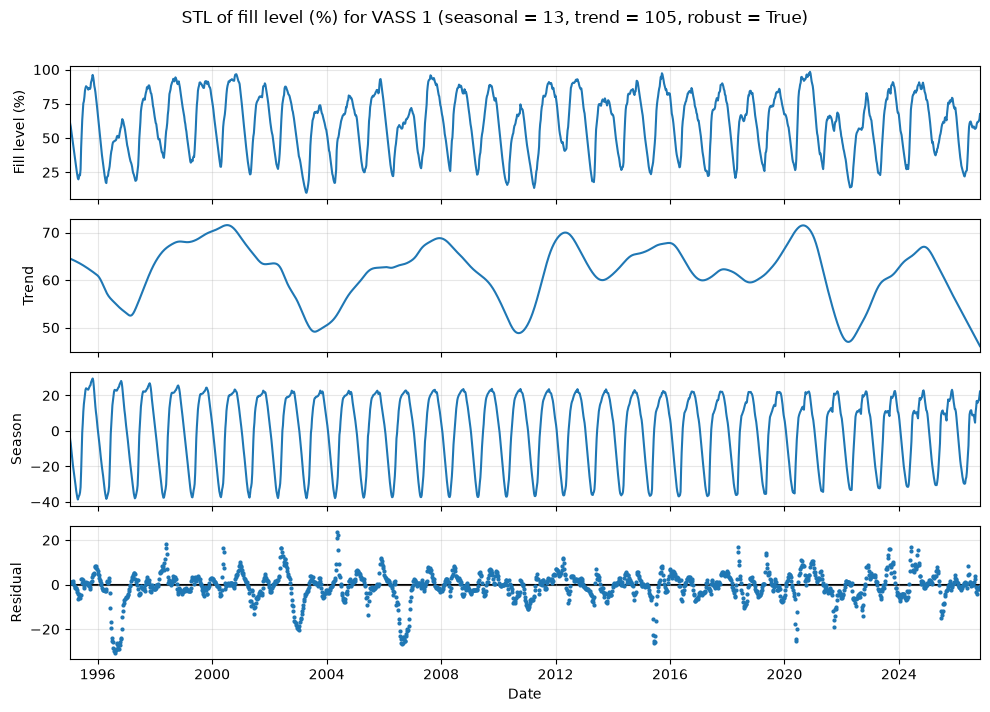

In [17]:
# Tester med standardverdiene
fig = stl_plot(reservoirs)
plt.show()

# Tester med robust STL og et annet område
fig = stl_plot(reservoirs, area="VASS 1", robust=True)
plt.show()

**Tolkning:** Sesongen er det tydeligste mønsteret. Magasinene er lavest om våren, før snøen smelter, og fullest om høsten. Trenden varierer mellom omtrent 50 og 70 %, med lave perioder rundt 1996, 2003 og 2010, som var tørre år. I VASS 1 (Øst) er også 2022 tydelig lav, året med lite nedbør og høye strømpriser i Sør-Norge. Resten viser de samme årene som store negative avvik. Trenden faller kraftig helt til slutt, men det skyldes at metoden har færre data å glatte over ved slutten av serien, så de siste ukene er usikre. Med `robust=True` påvirkes trend og sesong mindre av de store avvikene, så de havner i resten i stedet.

### Spektrogram

Spektrogrammet viser hvilke svingninger fyllingsgraden har, og hvordan de endrer seg over tid. Serien deles i overlappende vinduer, og for hvert vindu regnes styrken av hver frekvens ut med Short-Time Fourier Transform (STFT). Frekvensen er målt i svingninger per år, siden det er 52 målinger per år. Vinduslengden (`window_length`) og overlappet (`overlap`) er parametere, med to år og halvannet år som standard. Gjennomsnittet i hvert vindu trekkes fra, slik at selve nivået ikke overskygger svingningene.

In [18]:
from scipy.signal import stft


def spectrogram_plot(reservoirs, area="EL 3", window_length=104, overlap=78):
    """Spektrogram av fyllingsgraden for ett område.

    reservoirs:    magasinstatistikken fra NVE
    area:          område, f.eks. "EL 3" eller "VASS 1"
    window_length: lengden på hvert vindu i uker
    overlap:       antall uker vinduene overlapper (må være mindre enn window_length)

    Returnerer figuren.
    """
    series = (reservoirs[reservoirs["area"] == area]
              .sort_values("dato_Id")
              .set_index("dato_Id")["fyllingsgrad"] * 100)

    # STFT: fs=52 målinger per år, så frekvensen blir svingninger per år.
    # detrend="constant" trekker fra gjennomsnittet i hvert vindu.
    f, t, Zxx = stft(series.values, fs=52, nperseg=window_length,
                     noverlap=overlap, detrend="constant")

    # t er år fra starten av serien. Legger til startåret, så x-aksen viser årstall.
    years = series.index[0].year + t

    fig, ax = plt.subplots(figsize=(10, 4))
    mesh = ax.pcolormesh(years, f, np.abs(Zxx), shading="gouraud", cmap="viridis")
    fig.colorbar(mesh, ax=ax, label="Magnitude")
    ax.set_ylim(0, 6)   # viser de laveste frekvensene, der det meste skjer
    ax.set_title(f"Spectrogram of fill level for {area} "
                 f"(window = {window_length} weeks, overlap = {overlap} weeks)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Frequency (cycles per year)")
    plt.tight_layout()
    return fig

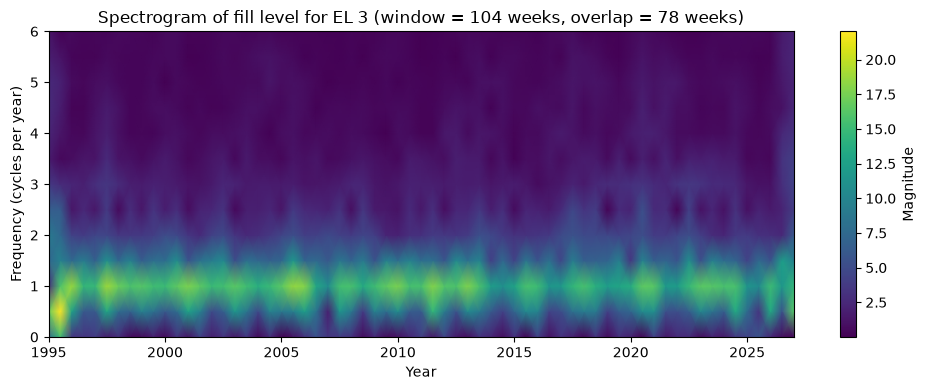

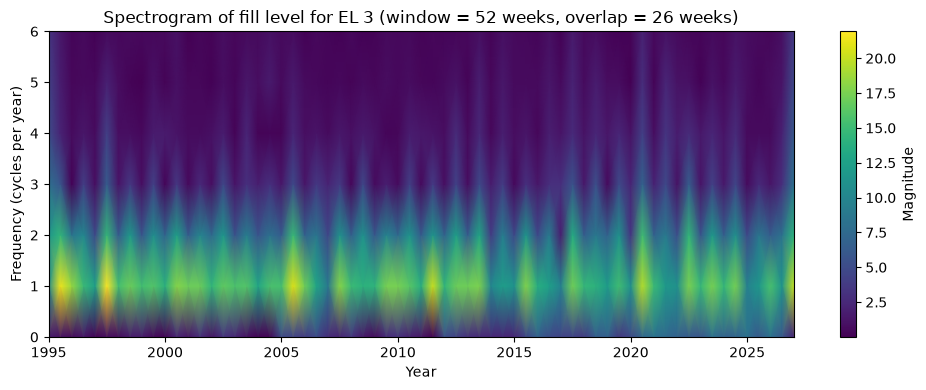

In [19]:
# Tester med standardverdiene
fig = spectrogram_plot(reservoirs)
plt.show()

# Tester med kortere vindu (ett år) og mindre overlapp
fig = spectrogram_plot(reservoirs, window_length=52, overlap=26)
plt.show()

**Tolkning:** Spektrogrammet har et tydelig bånd ved 1 svingning per år gjennom hele perioden. Det er den årlige syklusen, der magasinene fylles om våren og sommeren og tømmes om vinteren. Styrken varierer fra år til år: de lyseste områdene er år med stor forskjell mellom lav fylling om våren og høy fylling om høsten. Det svakere båndet ved 2 svingninger per år kommer av at kurven ikke er en ren bølge, fordi magasinene fylles raskt og tømmes sakte.

Med kortere vindu (52 uker) blir enkeltår tydeligere, men båndet blir bredere og mindre presist i frekvens. Lengre vinduer gir altså bedre oppløsning i frekvens, mens kortere vinduer gir bedre oppløsning i tid.